# Application of ANN in Streamflow Forecasting - live demo
ML Mini-Project (UE24CS352A), Problem 11. Station: USGS 02472000, Leaf River near Collins, MS.
Run all cells top to bottom (needs `data/streamflow_data.csv`; create it with `python download_data.py`).

In [1]:
import sys, json, os
sys.path.insert(0, '..')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from src.data_loader import load_master, chronological_split
from src.features import make_lagged, MaxScaler
from src.model import train_ann
from src.evaluate import regression_metrics, plot_eda
%matplotlib inline

## 1. Load and clean the data

In [2]:
df, report = load_master('../data/streamflow_data.csv')
print(json.dumps(report, indent=2))
df.describe()

{
  "rows_raw": 3653,
  "duplicate_dates": 0,
  "calendar_days_missing_rows": 0,
  "rainfall_mm_negative": 0,
  "rainfall_mm_missing": 3,
  "discharge_cfs_negative": 0,
  "discharge_cfs_missing": 0,
  "date_min": "2003-01-01",
  "date_max": "2012-12-31",
  "rows_clean": 3653
}


,rainfall_mm,discharge_cfs
count,3650.000000,3653.000000
mean,3.940260,858.024583
std,10.597651,1859.100855
min,0.000000,53.300000
25%,0.000000,135.000000
50%,0.000000,280.000000
75%,1.480000,689.000000
max,168.910000,29700.000000


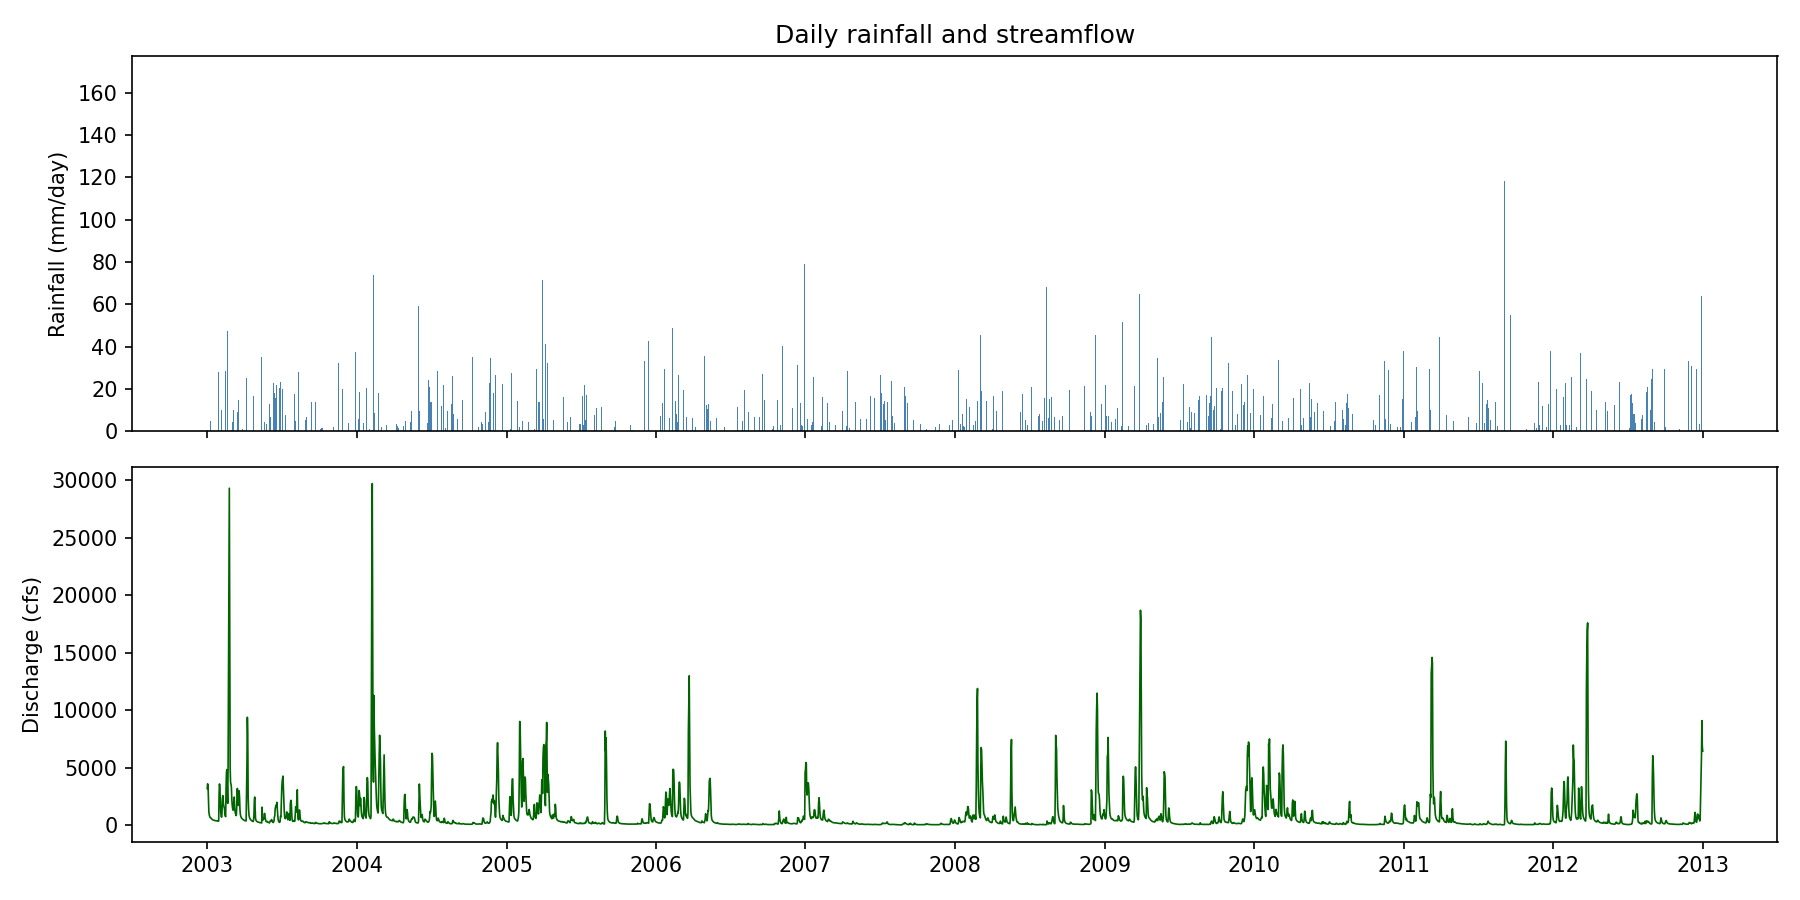

In [3]:
plot_eda(df, '/tmp/eda.png')
from IPython.display import Image; Image('/tmp/eda.png')

## 2. Lag features  Q(t) = f(R(t-1..t-m), Q(t-1..t-n))
Settings are read from `results/metrics/best_config.json` (written by `pipeline.py` after the validation-year search).
If that file is missing we fall back to m=3, n=4, hidden=12 (the combination reported by the Stanford reference).

In [4]:
cfg_path = '../results/metrics/best_config.json'
cfg = json.load(open(cfg_path)) if os.path.exists(cfg_path) else \
      {'m_rain_lags': 3, 'n_flow_lags': 4, 'hidden': [12], 'activation': 'logistic', 'learning_rate': 0.005, 'peak_threshold_cfs': 1500}
print(cfg)
lagged = make_lagged(df, cfg['m_rain_lags'], cfg['n_flow_lags'])
lagged.head()

{'m_rain_lags': 3, 'n_flow_lags': 2, 'hidden': [16, 8], 'activation': 'logistic', 'learning_rate': 0.005, 'peak_threshold_cfs': 1500.0, 'best_epoch': 200, 'train_q_max_cfs': 29700.0, 'train_r_max_mm': 168.91}


,R_lag1,R_lag2,R_lag3,Q_lag1,Q_lag2,target
date,,,,,,
2003-01-04,0.0,0.62,0.00,3450.0,3620.0,2330.0
2003-01-05,0.0,0.00,0.62,2330.0,3450.0,1180.0
2003-01-06,0.0,0.00,0.00,1180.0,2330.0,932.0
2003-01-07,0.0,0.00,0.00,932.0,1180.0,791.0
2003-01-08,0.0,0.00,0.00,791.0,932.0,705.0


## 3. Chronological split (past -> train, then validation, then test) and scaling fitted on train only

In [5]:
train, val, test = chronological_split(lagged)
print(len(train), len(val), len(test))
print('train', train.index.min().date(), '->', train.index.max().date())
print('val  ', val.index.min().date(), '->', val.index.max().date())
print('test ', test.index.min().date(), '->', test.index.max().date())
sc = MaxScaler().fit(train)
Xtr, ytr = sc.transform(train); Xva, yva = sc.transform(val); Xte, yte = sc.transform(test)

1455 365 1824
train 2003-01-04 -> 2006-12-31
val   2007-01-01 -> 2007-12-31
test  2008-01-01 -> 2012-12-31


## 4. Train the ANN (early stopping on the validation years)

best epoch: 200


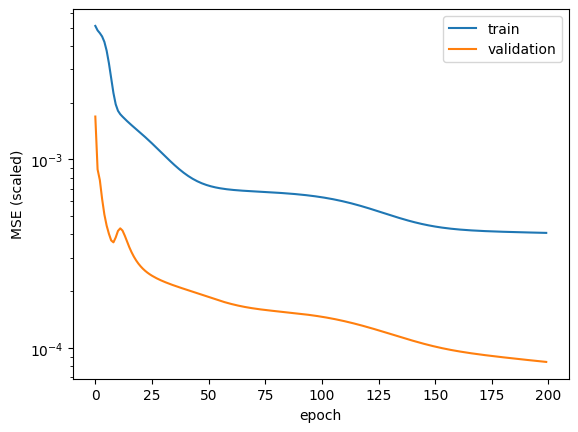

In [6]:
model, hist = train_ann(Xtr, ytr, Xva, yva, hidden=tuple(cfg['hidden']),
                        activation=cfg['activation'], lr=cfg['learning_rate'], seed=0)
print('best epoch:', hist['best_epoch'])
plt.plot(hist['train_mse'], label='train'); plt.plot(hist['val_mse'], label='validation')
plt.yscale('log'); plt.xlabel('epoch'); plt.ylabel('MSE (scaled)'); plt.legend(); plt.show()

## 5. Predict on the test years and evaluate against baselines

In [7]:
obs = test['target'].values
ann = np.clip(sc.inverse_target(model.predict(Xte)), 0, None)
lin = np.clip(sc.inverse_target(LinearRegression().fit(Xtr, ytr).predict(Xte)), 0, None)
pers = test['Q_lag1'].values
thr = cfg['peak_threshold_cfs']
pd.DataFrame({'Persistence': regression_metrics(obs, pers, thr),
              'Linear regression': regression_metrics(obs, lin, thr),
              'ANN': regression_metrics(obs, ann, thr)}).T.round(3)

,MAE,MSE,RMSE,R2_NSE,RMSE_pct_of_max,RMSE_peak,RMSE_nonpeak,n_peak_days,n_days
Persistence,278.897,730723.844,854.824,0.768,4.571,2366.179,213.827,225.0,1824.0
Linear regression,291.456,360911.140,600.759,0.886,3.213,1451.505,339.459,225.0,1824.0
ANN,237.734,344544.697,586.979,0.891,3.139,1528.194,253.789,225.0,1824.0


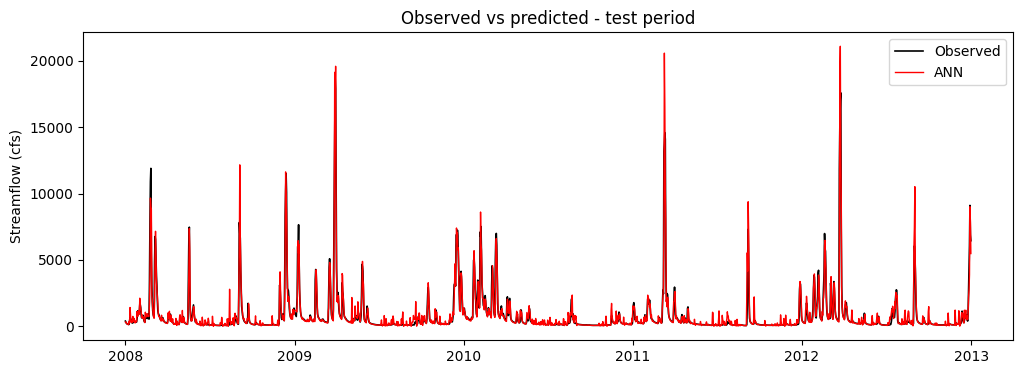

In [8]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(test.index, obs, 'k', lw=1.2, label='Observed'); ax.plot(test.index, ann, 'r', lw=1, label='ANN')
ax.set_ylabel('Streamflow (cfs)'); ax.set_title('Observed vs predicted - test period'); ax.legend(); plt.show()